In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn
%pip install matplotlib

## Project type: Data Analytics / Exploratory Data Analysis (EDA)
This notebook cleans the Travel dataset, handles missing values and outliers, visualizes distributions, and explores factors associated with product conversion (`ProdTaken`). It does not currently train or evaluate a machine-learning model. It could be extended into an ML project by training a classifier to predict `ProdTaken`.

**Input requirement:** `Travel.csv` must be in the notebook's working directory (or update `data_path` in the loading cell).

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from pathlib import Path
import os

sns.set_theme(style="whitegrid")


In [36]:
# If an import fails, run this in a separate notebook cell:
# %pip install pandas numpy matplotlib seaborn scikit-learn


In [37]:
pwd

'C:\\pushkar\\data analytics project'

In [38]:
# Keep Travel.csv in the same folder as this notebook, or update this path.
data_path = Path("Travel.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Travel.csv was not found. Put Travel.csv in the notebook's working folder "
        "or change data_path to the correct file location."
    )
TR = pd.read_csv(data_path)
print("Dataset shape:", TR.shape)


Dataset shape: (4888, 20)


In [39]:
TR.head(1)

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0


In [40]:
TR.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                object
CityTier                      int64
DurationOfPitch             float64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched               object
PreferredPropertyStar       float64
MaritalStatus                object
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                  object
MonthlyIncome               float64
dtype: object

In [41]:
#TR['age].astype(int) # found null values

In [42]:
TR.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

# mising value
1) Mean | Medium | Mode
2) Bfill | Ffill
3) Domain specific knowledge
4) Interpolation 

In [43]:
# Fill missing numeric values with the median and categorical values with the mode.
# Median is less sensitive to outliers than mean.
for col in TR.columns:
    if pd.api.types.is_numeric_dtype(TR[col]):
        if TR[col].isna().any():
            TR[col] = TR[col].fillna(TR[col].median())
    else:
        if TR[col].isna().any():
            modes = TR[col].mode(dropna=True)
            if not modes.empty:
                TR[col] = TR[col].fillna(modes.iloc[0])

TR.isnull().sum()


CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [44]:
TR.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [45]:
# TR.['age'].astype(int)

In [46]:
TR['Age']=TR['Age'].astype(int)

In [47]:
TR.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                           int64
TypeofContact                object
CityTier                      int64
DurationOfPitch             float64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched               object
PreferredPropertyStar       float64
MaritalStatus                object
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                  object
MonthlyIncome               float64
dtype: object

In [48]:
# Convert only whole-number-like numeric columns to integers; preserve income/continuous measures.
for col in TR.select_dtypes(include="number").columns:
    if col not in ["MonthlyIncome"] and TR[col].notna().all() and np.allclose(TR[col] % 1, 0):
        TR[col] = TR[col].astype("int64")
TR.dtypes


CustomerID                    int64
ProdTaken                     int64
Age                           int64
TypeofContact                object
CityTier                      int64
DurationOfPitch               int64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups             int64
ProductPitched               object
PreferredPropertyStar         int64
MaritalStatus                object
NumberOfTrips                 int64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting      int64
Designation                  object
MonthlyIncome               float64
dtype: object

In [50]:
TR.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                           int64
TypeofContact                object
CityTier                      int64
DurationOfPitch               int64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups             int64
ProductPitched               object
PreferredPropertyStar         int64
MaritalStatus                object
NumberOfTrips                 int64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting      int64
Designation                  object
MonthlyIncome               float64
dtype: object

In [51]:
# Recheck data types after cleaning.
TR.dtypes


CustomerID                    int64
ProdTaken                     int64
Age                           int64
TypeofContact                object
CityTier                      int64
DurationOfPitch               int64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups             int64
ProductPitched               object
PreferredPropertyStar         int64
MaritalStatus                object
NumberOfTrips                 int64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting      int64
Designation                  object
MonthlyIncome               float64
dtype: object

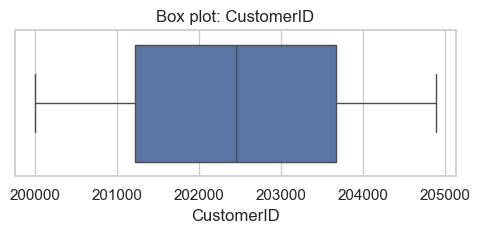

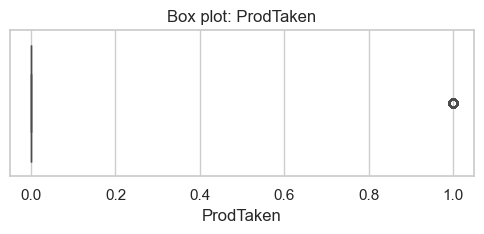

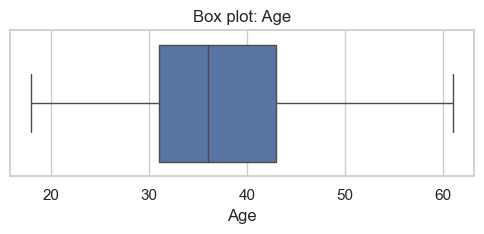

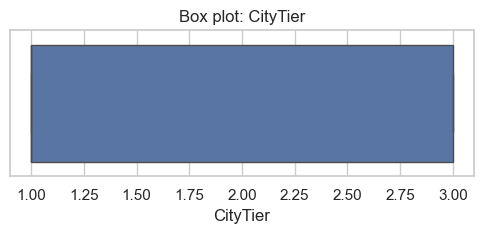

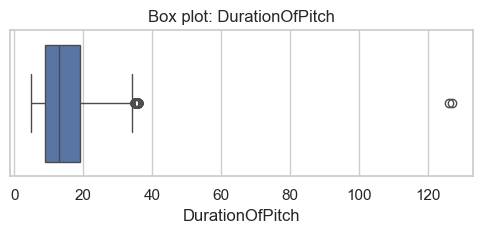

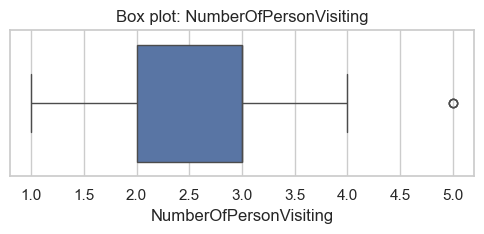

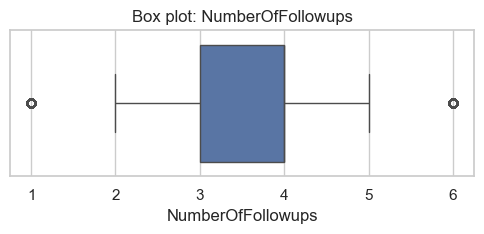

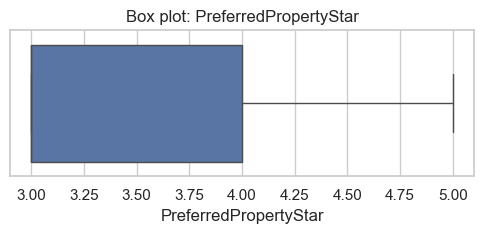

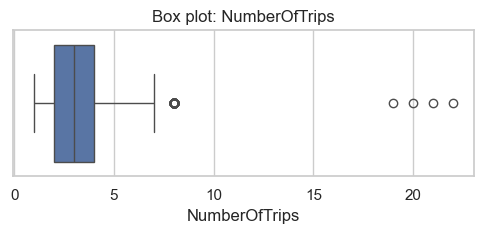

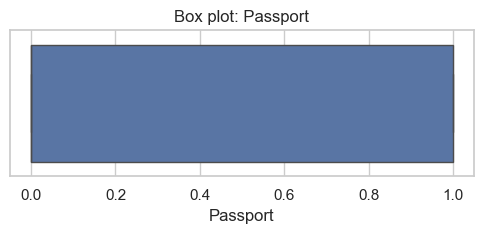

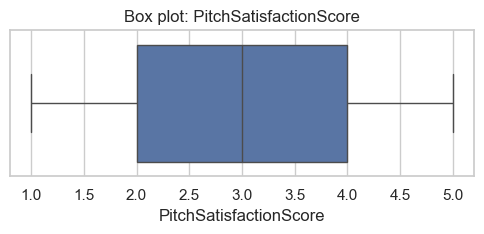

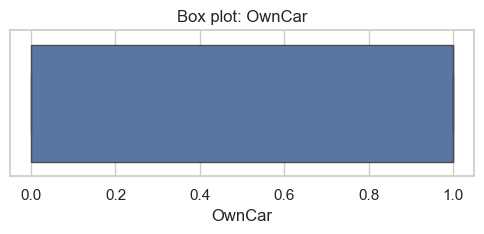

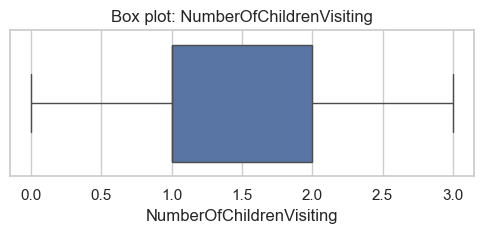

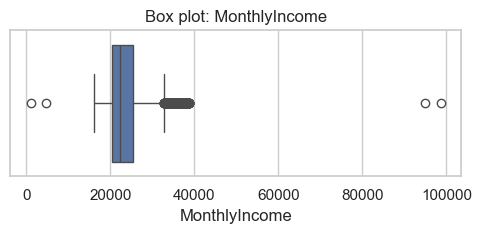

In [52]:
# Box plots for numeric columns only.
for col in TR.select_dtypes(include="number").columns:
    plt.figure(figsize=(5, 2.5))
    sns.boxplot(x=TR[col])
    plt.title(f"Box plot: {col}")
    plt.tight_layout()
    plt.show()


In [53]:
TR1 = TR.copy()

IQR method

In [54]:
# IQR outlier filtering on continuous numeric features only.
# Do not use IDs or the target column to decide which rows are outliers.
TR1 = TR.copy()
exclude_outlier_cols = {"CustomerID", "customerID", "ProdTaken"}
numeric_cols = [c for c in TR1.select_dtypes(include="number").columns
                if c not in exclude_outlier_cols]
for col in numeric_cols:
    q1, q3 = TR1[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        continue
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    TR1 = TR1[TR1[col].between(lower_fence, upper_fence)]
print("Rows retained after IQR filtering:", len(TR1), "of", len(TR))


Rows retained after IQR filtering: 4029 of 4888


In [55]:
TR1.shape[0] / TR.shape[0]

0.8242635024549918

In [56]:
TR1.shape[0] 

4029

# Z score method 

In [57]:
# emperical formula says if data is between -3 to +3 standard deviation 
# then 99.7% data is without outlier 

In [58]:
# step 1 [standardization of all numeric columns and will create a copy ]
# step2 [ apply filter of -3 to +3 standard deviation ]
# step3 [ drop all columns which are in standardize form]

In [59]:
TR2 = TR.copy()

In [60]:
# Z-score filtering for numeric feature columns (excluding ID and target).
# This is an alternative to IQR filtering; compare results before choosing one.
TR2 = TR.copy()
exclude_outlier_cols = {"CustomerID", "customerID", "ProdTaken"}
numeric_cols = [c for c in TR2.select_dtypes(include="number").columns
                if c not in exclude_outlier_cols]
if numeric_cols:
    z_scores = (TR2[numeric_cols] - TR2[numeric_cols].mean()) / TR2[numeric_cols].std(ddof=0).replace(0, np.nan)
    keep_rows = z_scores.abs().le(3).fillna(True).all(axis=1)
    TR2 = TR2.loc[keep_rows].copy()
print("Rows retained after Z-score filtering:", len(TR2), "of", len(TR))


Rows retained after Z-score filtering: 4878 of 4888


In [61]:
TR2.shape

(4878, 20)

In [62]:
TR2.shape[0] / TR.shape[0]

0.9979541734860884

In [63]:
TR.shape

(4888, 20)

# visualization 

In [64]:
# for categorical analysis using count plot to check 
# area of distribution between the categories

In [65]:
TR['Gender'].unique()

array(['Female', 'Male', 'Fe Male'], dtype=object)

In [66]:
# Normalize common spelling variation if this category exists.
if "Gender" in TR2.columns:
    TR2["Gender"] = TR2["Gender"].replace({"Fe Male": "Female"})


C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


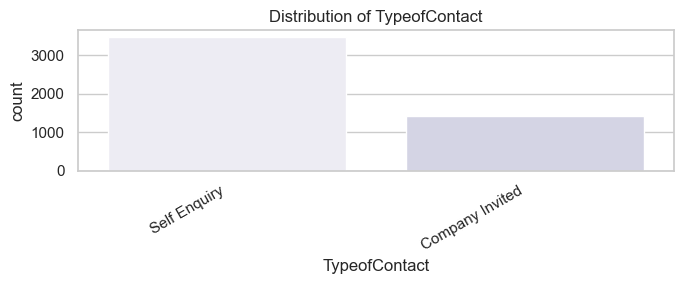

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


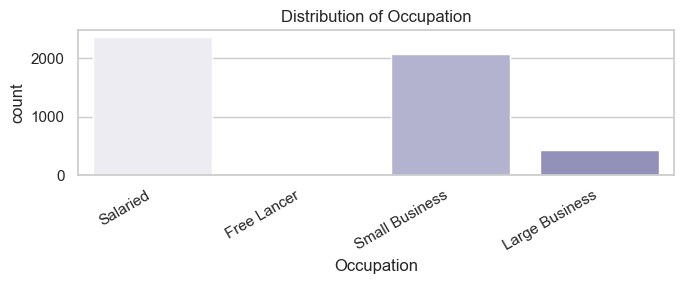

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


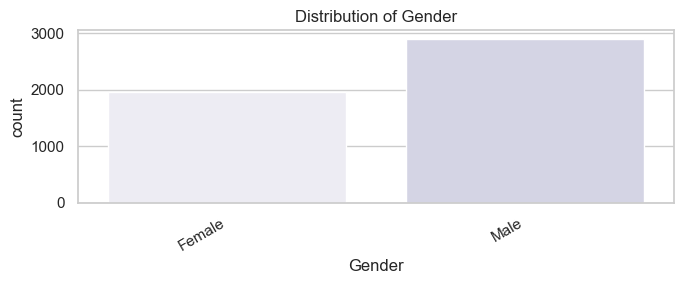

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


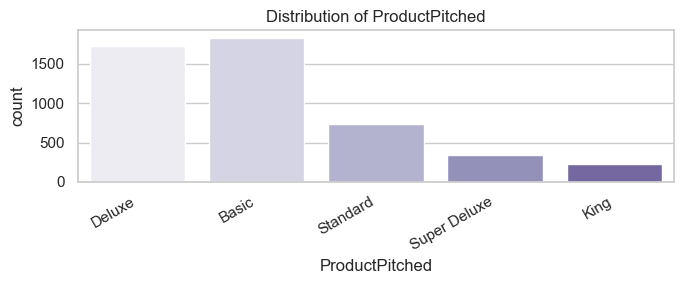

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


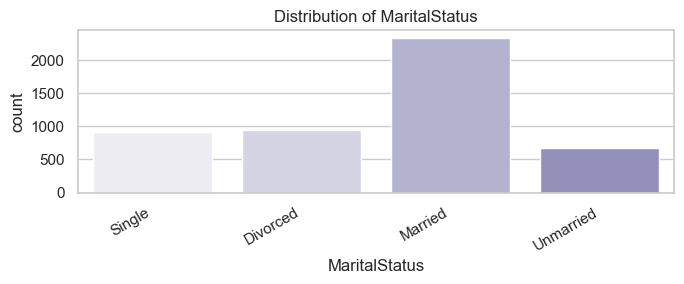

C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=TR2, x=col, palette=palette)
C:\Users\pc\AppData\Local\Temp\ipykernel_11104\2910135047.py:5: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.countplot(data=TR2, x=col, palette=palette)


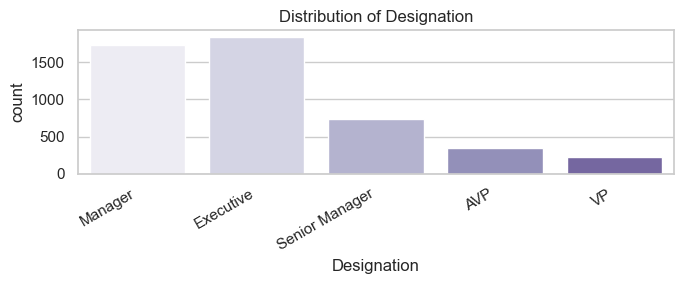

In [67]:
# Count plots for categorical columns (pandas uses dtype 'object' or 'category').
palette = sns.color_palette("Purples", 6)
for col in TR2.select_dtypes(include=["object", "category", "bool"]).columns:
    plt.figure(figsize=(7, 3))
    sns.countplot(data=TR2, x=col, palette=palette)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


In [68]:
palette

[(0.9265974625144175, 0.919769319492503, 0.9557093425605536),
 (0.8207612456747405, 0.8218992695117262, 0.9044982698961938),
 (0.6878892733564014, 0.6835832372164552, 0.829834678969627),
 (0.5513264129181085, 0.537916186082276, 0.7524490580545944),
 (0.440722798923491, 0.36772010765090346, 0.6653902345251825),
 (0.3405767012687428, 0.1742560553633218, 0.5709342560553633)]

In [69]:
TR2.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

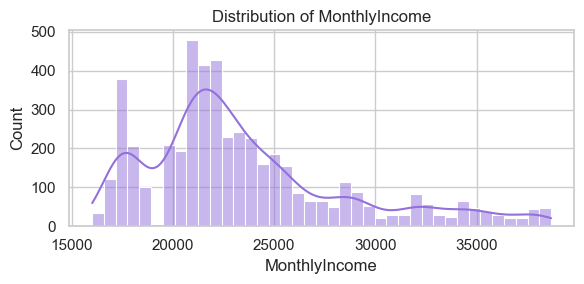

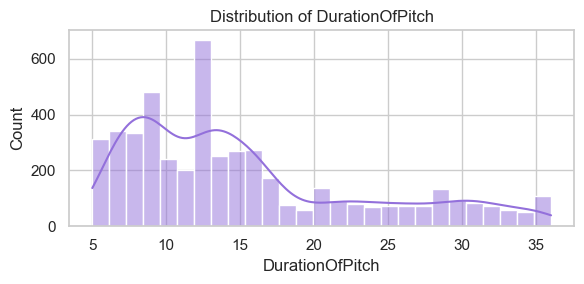

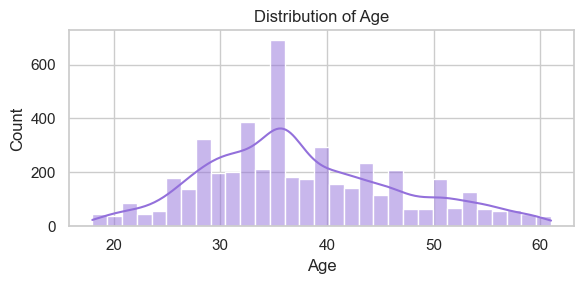

In [70]:
# Histograms for selected continuous variables that are present in the dataset.
for col in ["MonthlyIncome", "DurationOfPitch", "Age"]:
    if col in TR2.columns and pd.api.types.is_numeric_dtype(TR2[col]):
        plt.figure(figsize=(6, 3))
        sns.histplot(data=TR2, x=col, kde=True, color="mediumpurple")
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()


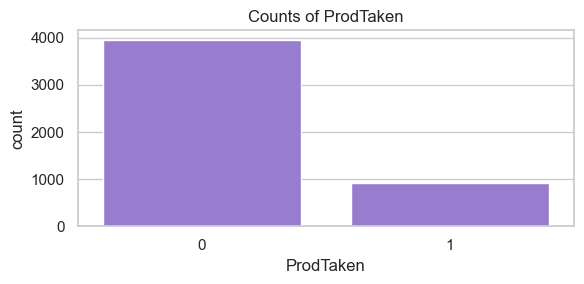

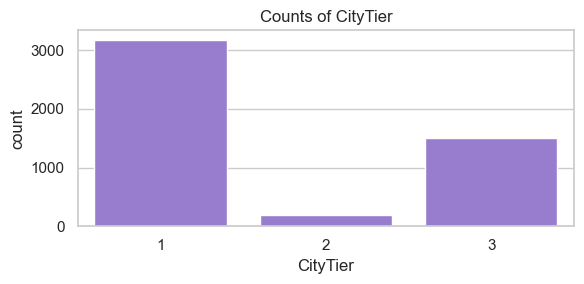

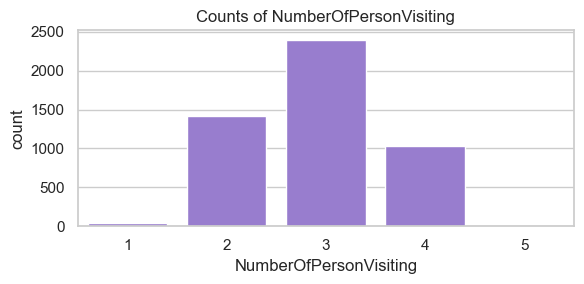

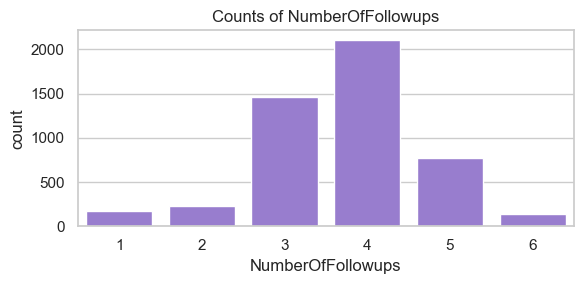

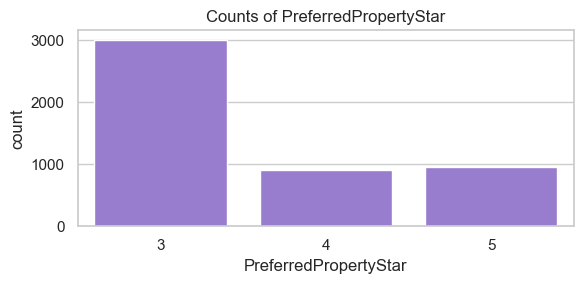

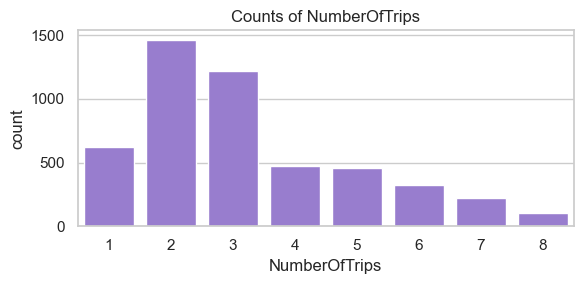

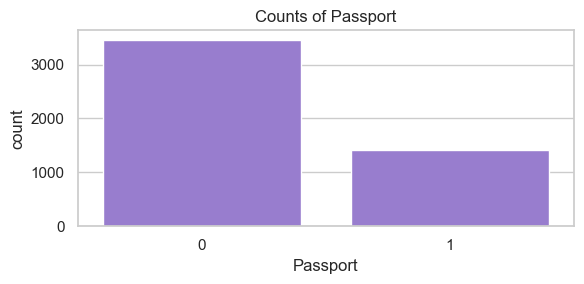

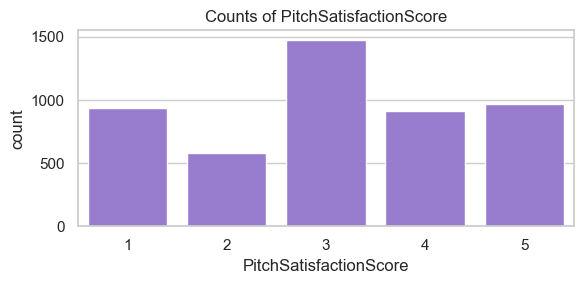

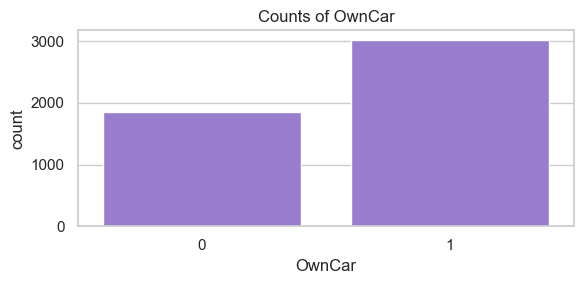

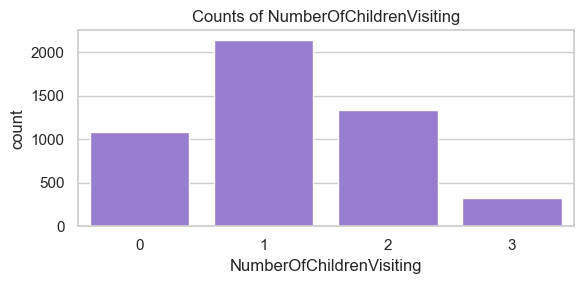

In [71]:
# Count plots for numeric categorical-like columns, excluding continuous values and IDs.
exclude_plot_cols = {"MonthlyIncome", "CustomerID", "customerID", "DurationOfPitch", "Age"}
for col in TR2.select_dtypes(include="number").columns:
    if col not in exclude_plot_cols and TR2[col].nunique() <= 20:
        plt.figure(figsize=(6, 3))
        sns.countplot(data=TR2, x=col, color="mediumpurple")
        plt.title(f"Counts of {col}")
        plt.tight_layout()
        plt.show()


# find out influencing factors for conversion in calls ?

In [72]:
Total_conversion = TR['ProdTaken'].mean()

In [73]:
round(Total_conversion,2) # in total 15% calls are getting converted 

np.float64(0.19)

In [74]:
TR2_type = TR2.groupby('TypeofContact').agg({'ProdTaken':'mean'}).reset_index()

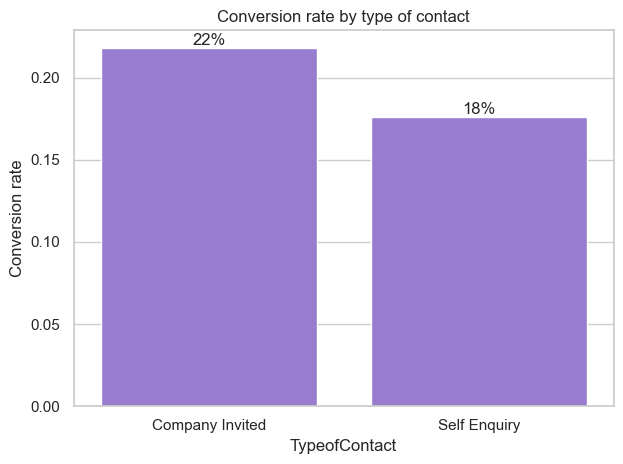

In [75]:
if "TypeofContact" in TR2.columns and "ProdTaken" in TR2.columns:
    TR2_type = TR2.groupby("TypeofContact", dropna=False, as_index=False)["ProdTaken"].mean()
    ax = sns.barplot(data=TR2_type, x="TypeofContact", y="ProdTaken", color="mediumpurple")
    ax.set_ylabel("Conversion rate")
    ax.set_title("Conversion rate by type of contact")
    ax.bar_label(ax.containers[0], fmt="%.0f%%", labels=[f"{v:.0%}" for v in TR2_type["ProdTaken"]])
    plt.tight_layout()
    plt.show()


In [76]:
TR2['TypeofContact'].value_counts()

TypeofContact
Self Enquiry       3465
Company Invited    1413
Name: count, dtype: int64

In [77]:
TR.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

In [78]:
# Separate categorical/low-cardinality analysis from continuous numeric features.
continuous_cols = [c for c in ["Age", "MonthlyIncome", "DurationOfPitch"] if c in TR2.columns]
cat_TR2 = TR2.drop(columns=continuous_cols, errors="ignore").copy()


In [79]:
# for col in cat_TR2:
#     if col != 'ProdTaken':
#         group_df = cat_TR2.groupby(col)['ProdTaken'].mean().reset_index()
#         ax = sns.barplot(data=group_df, x=col, y='ProdTaken', palette=palette)
#         for i in ax.containers:
#             ax.bar_label(i, fmt='{:.0%}')
#         plt.show()

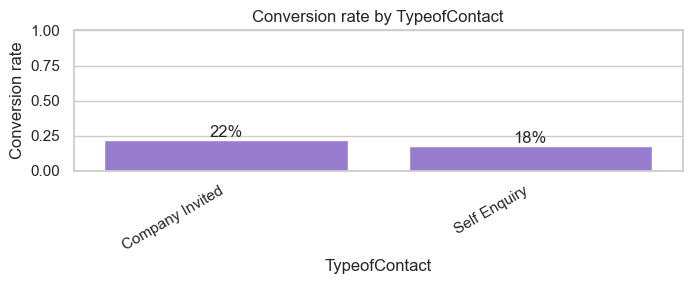

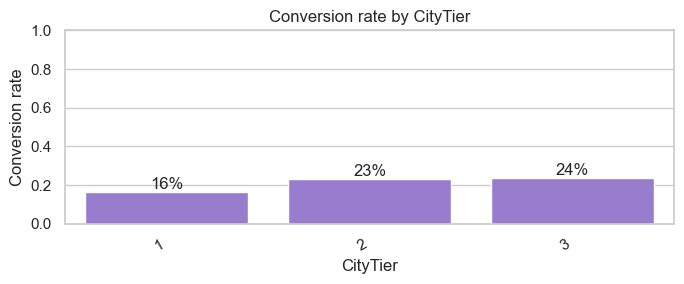

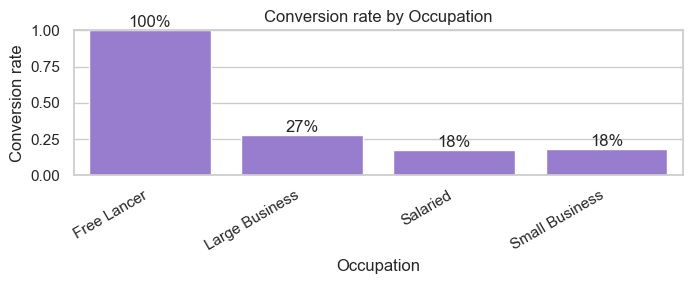

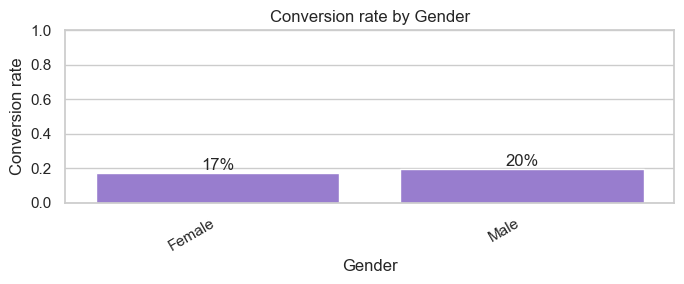

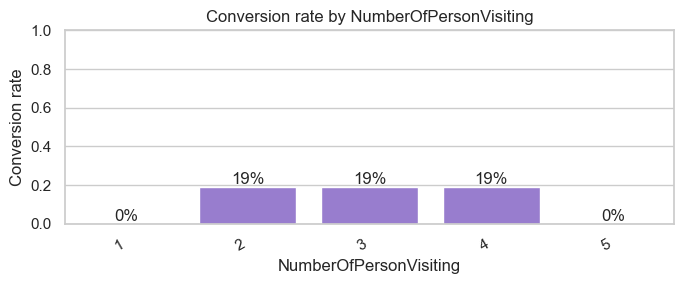

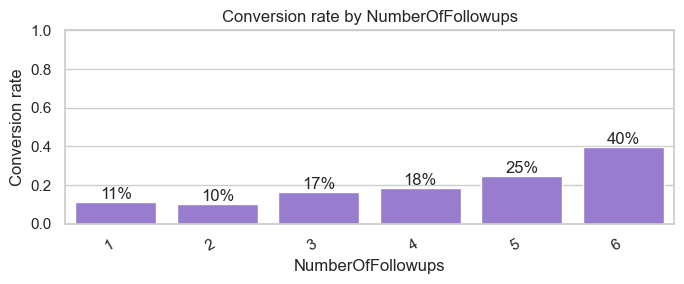

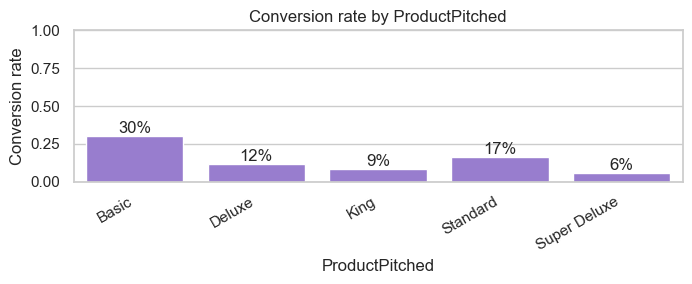

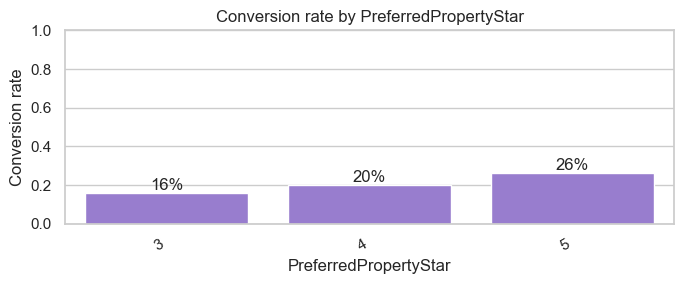

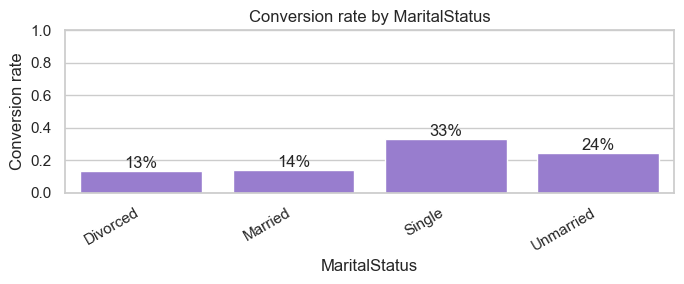

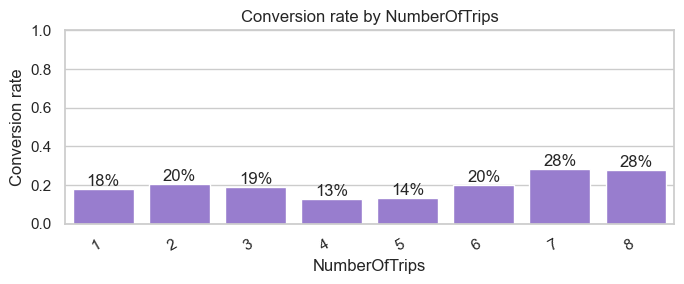

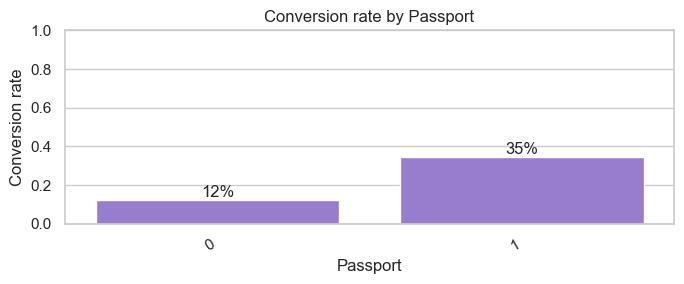

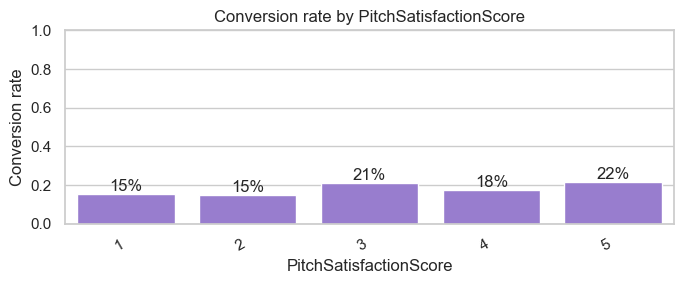

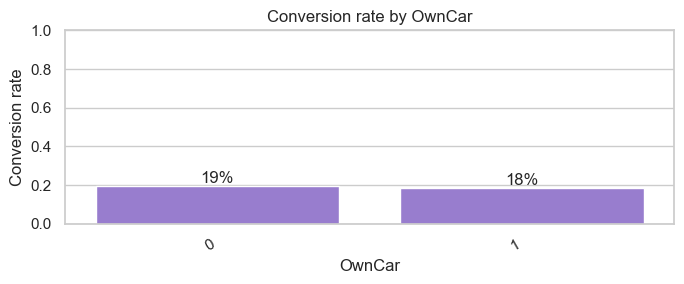

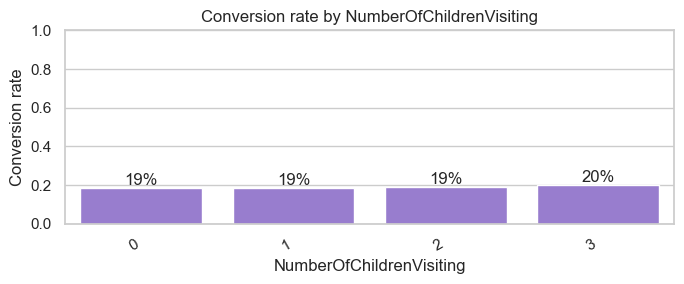

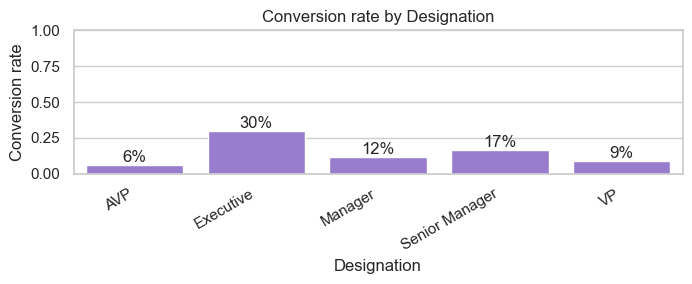

In [80]:
# Conversion rate by category. Limit to low-cardinality columns for readable plots.
if "ProdTaken" in cat_TR2.columns:
    for col in cat_TR2.columns:
        if col == "ProdTaken" or cat_TR2[col].nunique(dropna=False) > 20:
            continue
        group_df = cat_TR2.groupby(col, dropna=False, as_index=False)["ProdTaken"].mean()
        plt.figure(figsize=(7, 3))
        ax = sns.barplot(data=group_df, x=col, y="ProdTaken", color="mediumpurple")
        ax.set_ylabel("Conversion rate")
        ax.set_title(f"Conversion rate by {col}")
        ax.set_ylim(0, 1)
        ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in group_df["ProdTaken"]])
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()


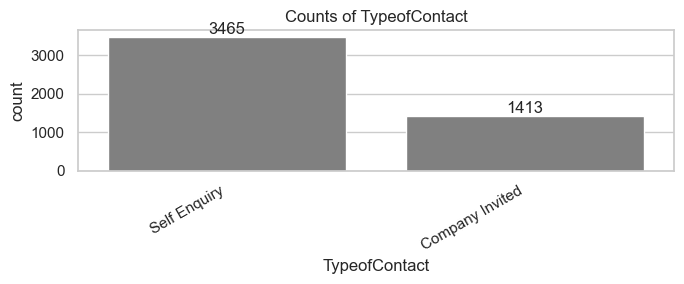

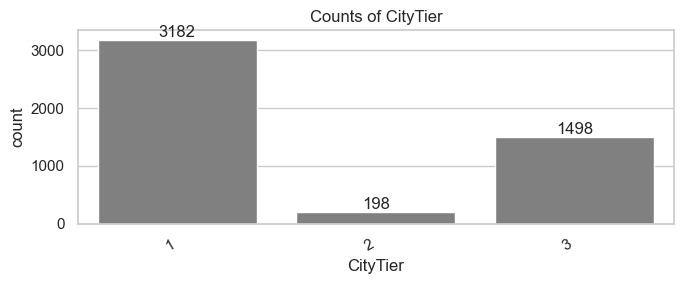

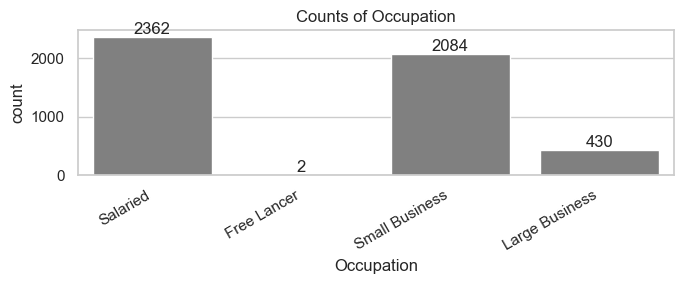

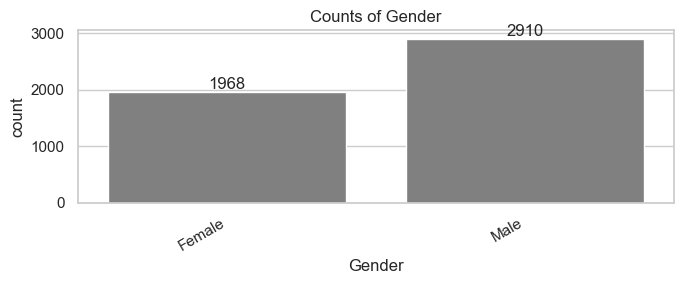

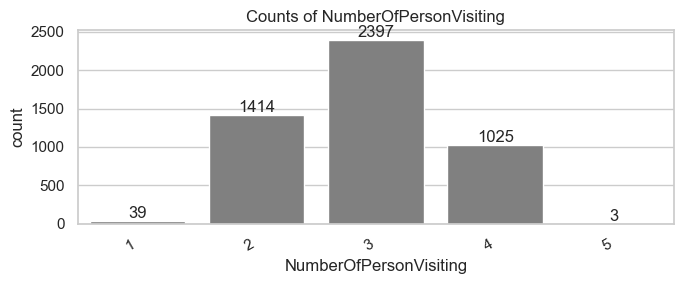

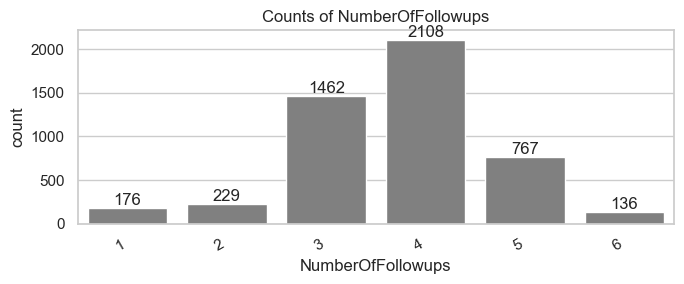

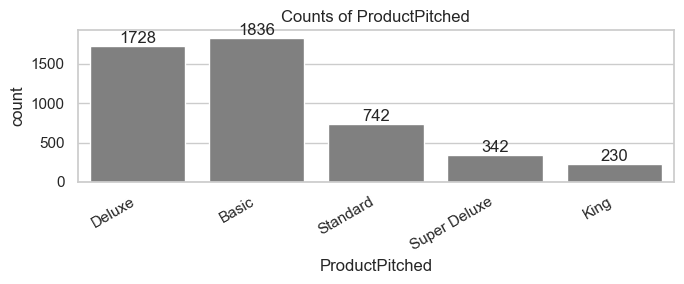

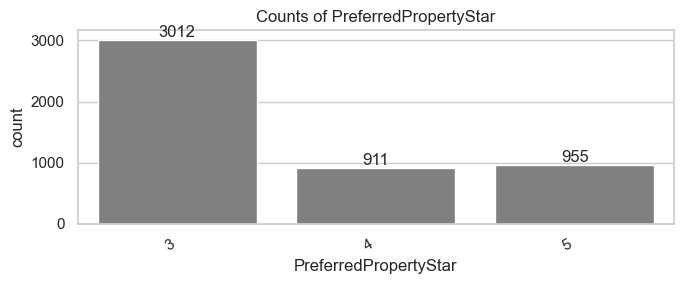

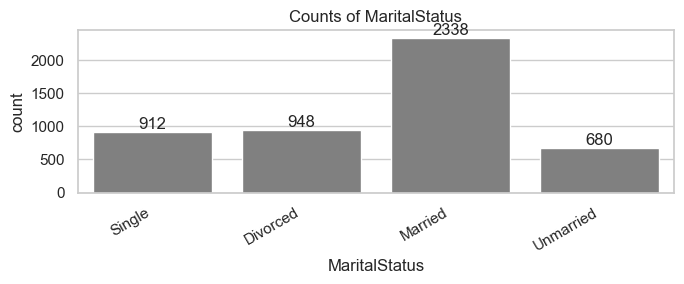

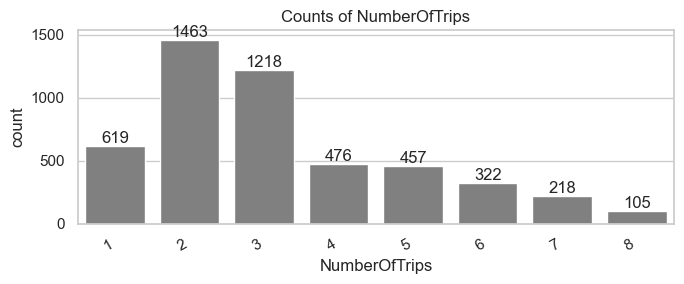

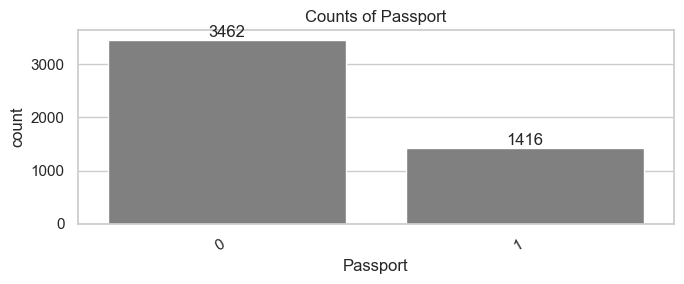

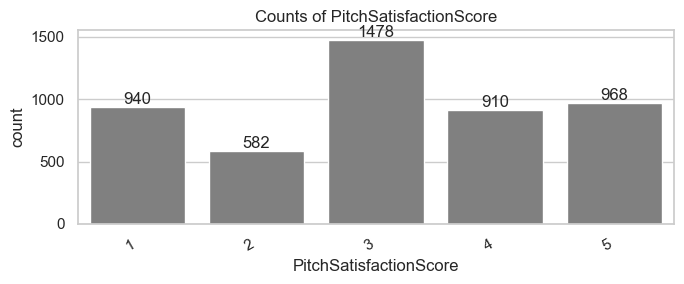

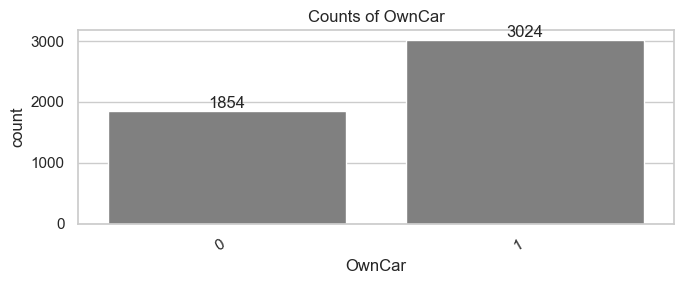

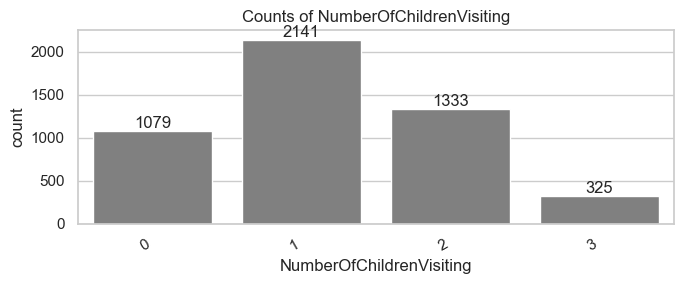

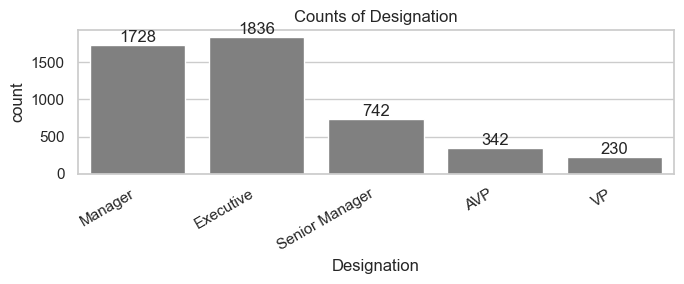

In [81]:
# Category frequency plots, excluding the target and customer identifier.
for col in cat_TR2.columns:
    if col in {"ProdTaken", "CustomerID", "customerID"} or cat_TR2[col].nunique(dropna=False) > 20:
        continue
    plt.figure(figsize=(7, 3))
    ax = sns.countplot(data=cat_TR2, x=col, color="grey")
    ax.bar_label(ax.containers[0])
    plt.title(f"Counts of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


In [82]:
TR2.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

In [83]:
Num_TR2 = TR2[['MonthlyIncome','DurationOfPitch','Age']]

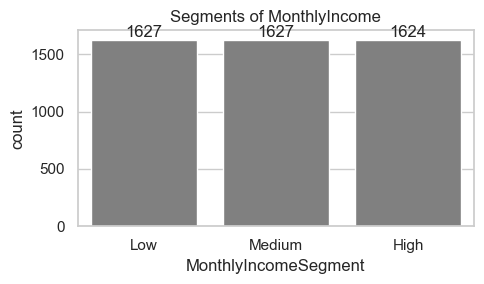

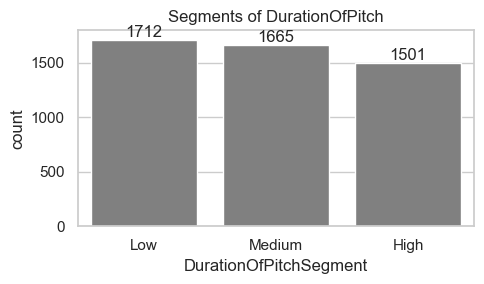

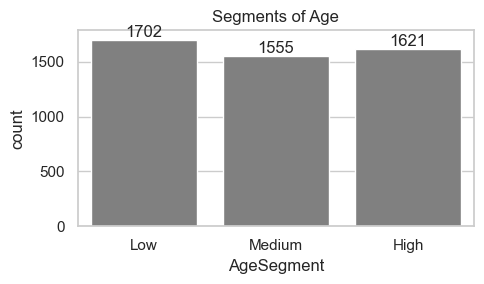

In [84]:
# Bin selected continuous variables into low/medium/high segments.
Num_TR2 = TR2[[c for c in ["MonthlyIncome", "DurationOfPitch", "Age"] if c in TR2.columns]].copy()
for col in list(Num_TR2.columns):
    segment_col = col + "Segment"
    try:
        Num_TR2[segment_col] = pd.qcut(Num_TR2[col], q=3, labels=["Low", "Medium", "High"], duplicates="drop")
    except ValueError:
        Num_TR2[segment_col] = pd.cut(Num_TR2[col], bins=3, labels=["Low", "Medium", "High"], duplicates="drop")
    plt.figure(figsize=(5, 3))
    ax = sns.countplot(data=Num_TR2, x=segment_col, color="grey")
    ax.bar_label(ax.containers[0])
    plt.title(f"Segments of {col}")
    plt.tight_layout()
    plt.show()


In [85]:
if "ProdTaken" in TR2.columns:
    Num_TR2["ProdTaken"] = TR2["ProdTaken"].values


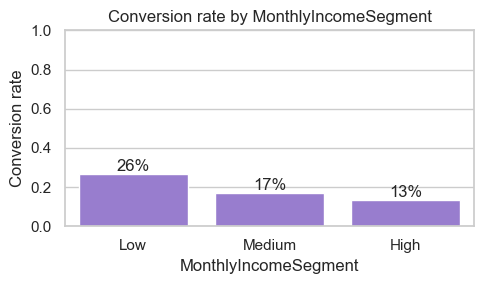

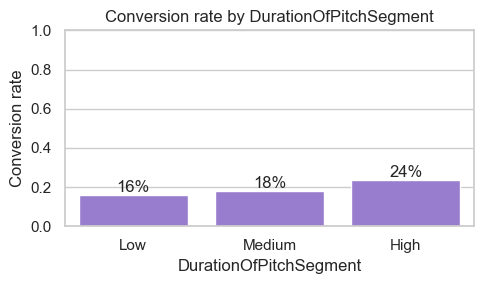

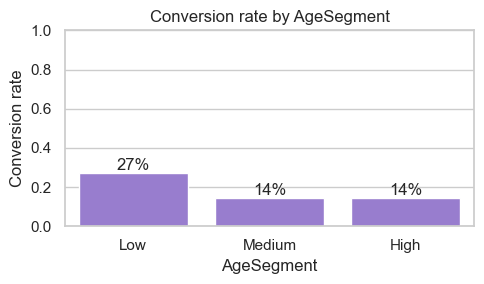

In [86]:
# Conversion rate by numeric segment.
if "ProdTaken" in Num_TR2.columns:
    for segment_col in [c for c in Num_TR2.columns if c.endswith("Segment")]:
        group_df = Num_TR2.groupby(segment_col, observed=False, as_index=False)["ProdTaken"].mean()
        plt.figure(figsize=(5, 3))
        ax = sns.barplot(data=group_df, x=segment_col, y="ProdTaken", color="mediumpurple")
        ax.set_ylabel("Conversion rate")
        ax.set_ylim(0, 1)
        ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" if pd.notna(v) else "" for v in group_df["ProdTaken"]])
        plt.title(f"Conversion rate by {segment_col}")
        plt.tight_layout()
        plt.show()


In [87]:
import os
os.makedirs('Travel_Report_plots',exist_ok=True)

In [88]:
plt_counter=1

In [89]:
# The draw_event callback in the original version had a typo and could save repeatedly.
# Saving plots explicitly is more reliable; see the plotting loop below.
os.makedirs("Travel_Report_plots", exist_ok=True)


In [90]:
# Helper function for explicitly saving a figure without draw-event recursion.
plt_counter = 0
def save_plot(fig, prefix="plot"):
    global plt_counter
    os.makedirs("Travel_Report_plots", exist_ok=True)
    filename = os.path.join("Travel_Report_plots", f"{prefix}_{plt_counter}.png")
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt_counter += 1
    return filename


Saved: Travel_Report_plots\boxplot_0.png


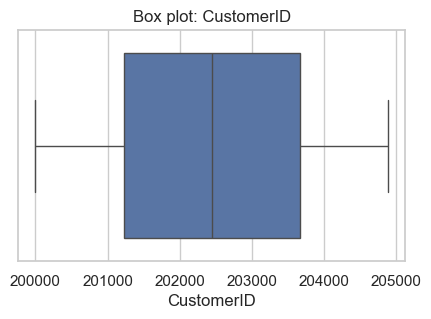

Saved: Travel_Report_plots\boxplot_1.png


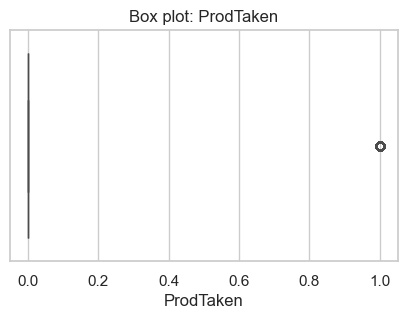

Saved: Travel_Report_plots\boxplot_2.png


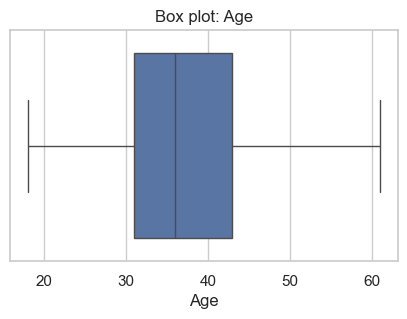

Saved: Travel_Report_plots\boxplot_3.png


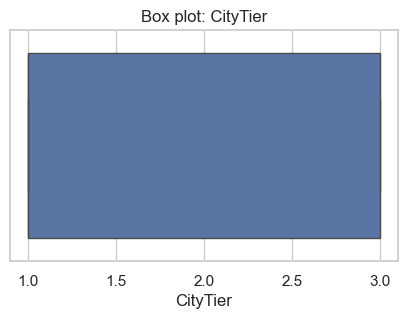

Saved: Travel_Report_plots\boxplot_4.png


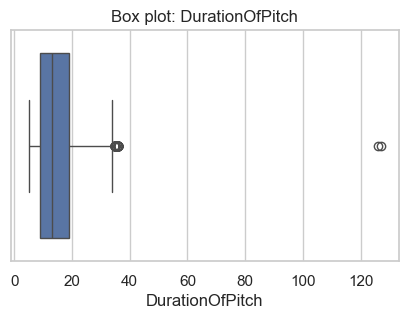

Saved: Travel_Report_plots\boxplot_5.png


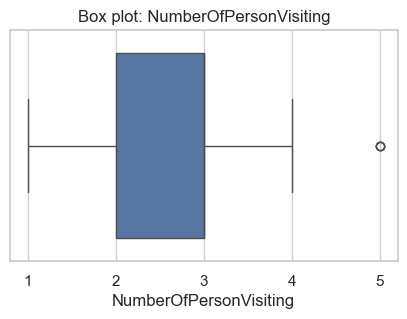

Saved: Travel_Report_plots\boxplot_6.png


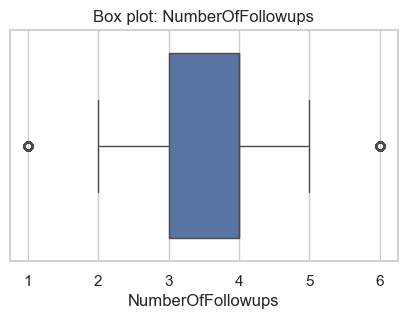

Saved: Travel_Report_plots\boxplot_7.png


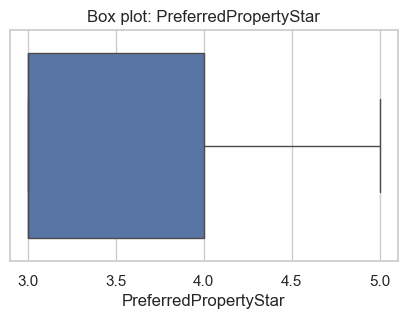

Saved: Travel_Report_plots\boxplot_8.png


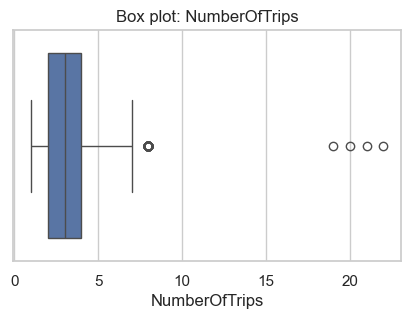

Saved: Travel_Report_plots\boxplot_9.png


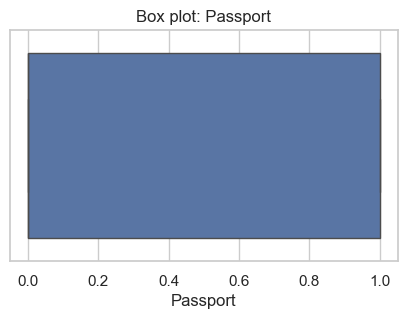

Saved: Travel_Report_plots\boxplot_10.png


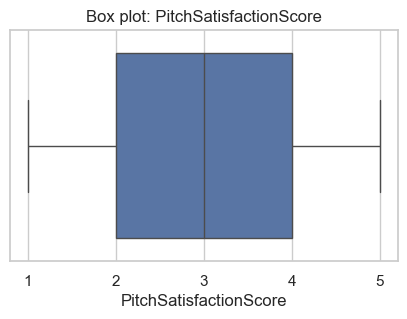

Saved: Travel_Report_plots\boxplot_11.png


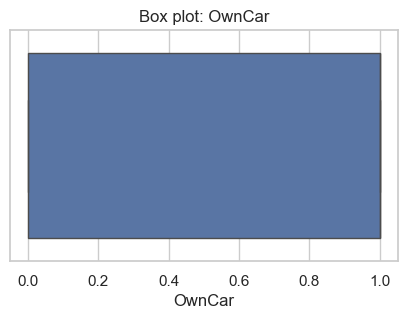

Saved: Travel_Report_plots\boxplot_12.png


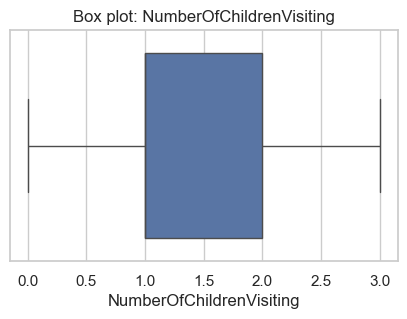

Saved: Travel_Report_plots\boxplot_13.png


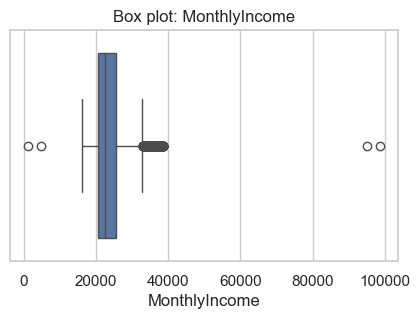

In [91]:
# Example: create and save box plots for each numeric column.
for col in TR.select_dtypes(include="number").columns:
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.boxplot(x=TR[col], ax=ax)
    ax.set_title(f"Box plot: {col}")
    saved_path = save_plot(fig, prefix="boxplot")
    print("Saved:", saved_path)
    plt.show()
    plt.close(fig)
